<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Pratica7Quest%C3%A3o5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

fs = 8192 Hz, N = 73113 amostras, duração = 8.92 s
Potência de x: 0.03851   interferência 100 Hz: 0.00125   interferência 2 kHz: 0.00281

(a) Sinal contaminado
sigma^2 = 0.01   potência do ruído = 0.0100   SNR de entrada =   4.35 dB
sigma^2 = 0.1    potência do ruído = 0.1002   SNR de entrada =  -4.33 dB
sigma^2 = 1.0    potência do ruído = 1.0046   SNR de entrada = -14.18 dB


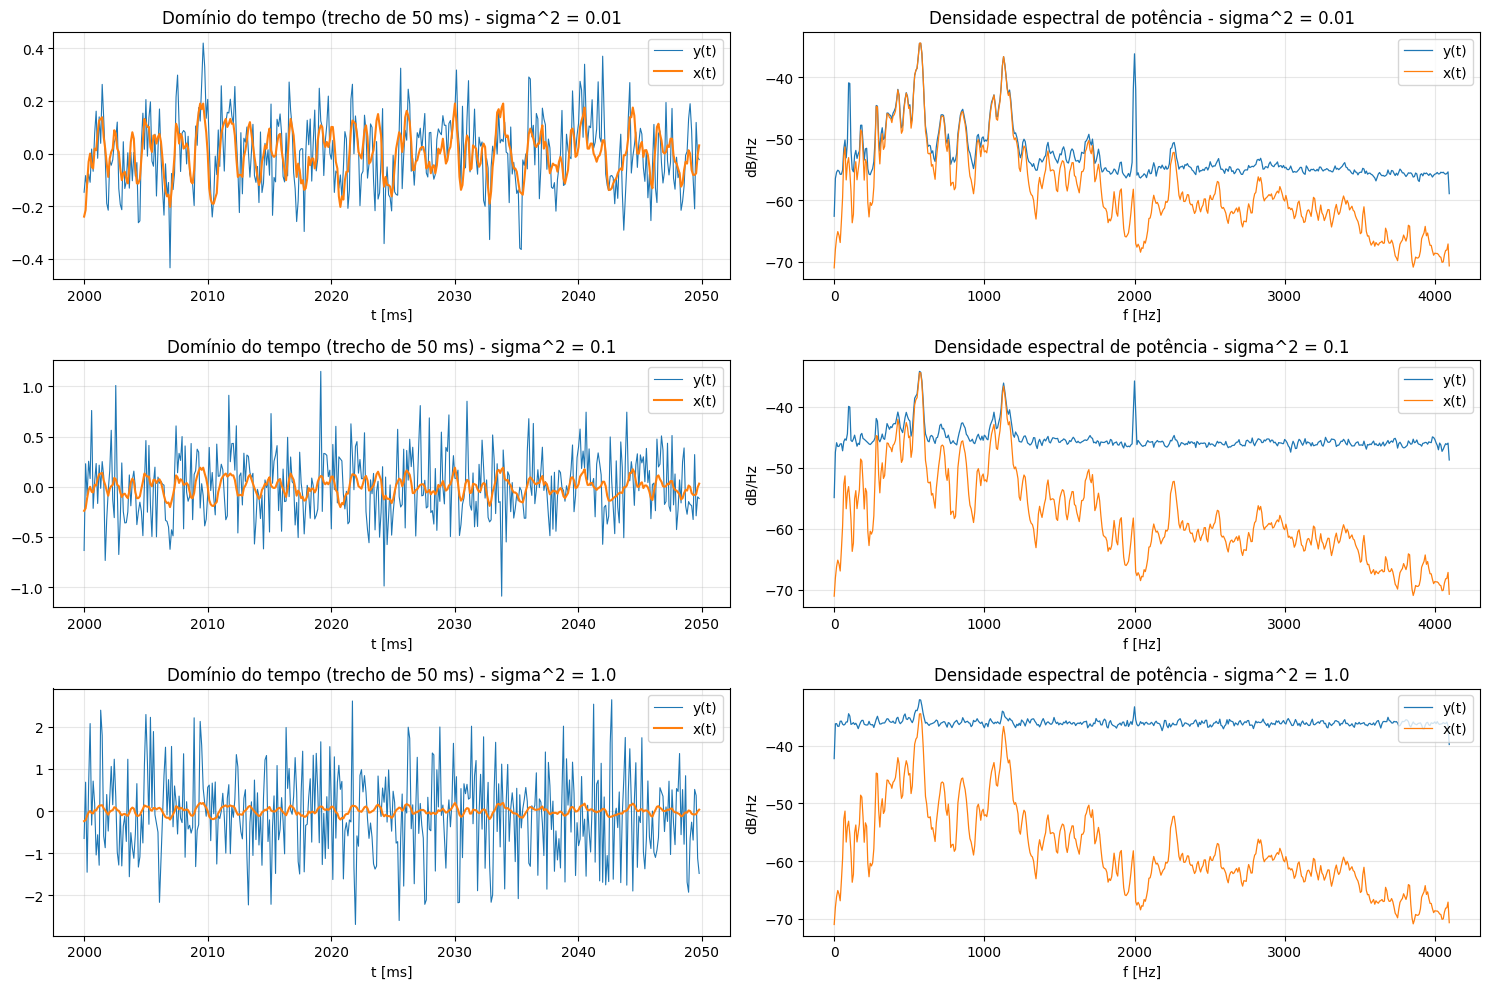

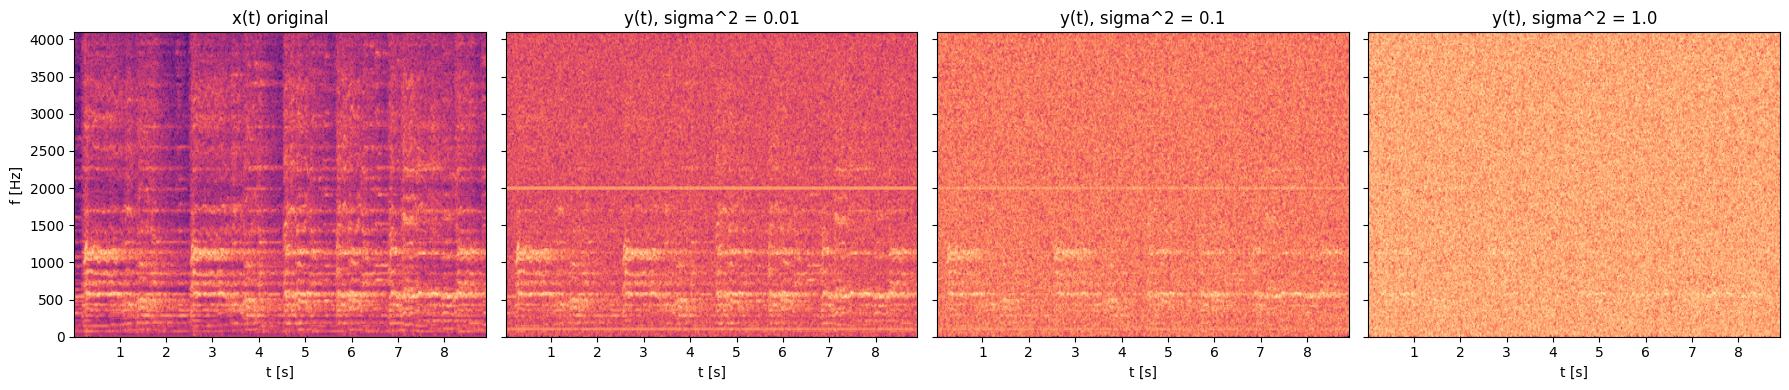

Áudio original:


Áudio contaminado, sigma^2 = 0.01:


Áudio contaminado, sigma^2 = 0.1:


Áudio contaminado, sigma^2 = 1.0:



(b) Análise espectral
90% da energia de x(t) abaixo de 1191 Hz
95% da energia de x(t) abaixo de 1719 Hz
99% da energia de x(t) abaixo de 3113 Hz
sigma^2 = 0.01: densidade do ruído = -56.1 dB/Hz (unilateral); ruído acima de 1800 Hz = 56% da potência total do ruído
sigma^2 = 0.1: densidade do ruído = -46.1 dB/Hz (unilateral); ruído acima de 1800 Hz = 56% da potência total do ruído
sigma^2 = 1.0: densidade do ruído = -36.1 dB/Hz (unilateral); ruído acima de 1800 Hz = 56% da potência total do ruído


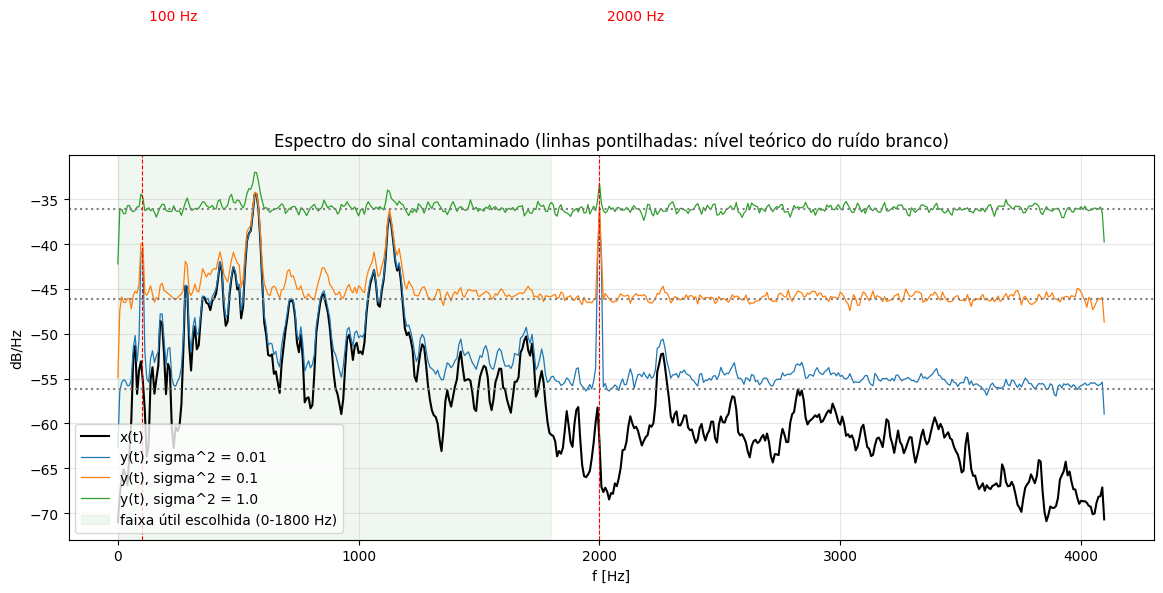

In [2]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

url = "https://raw.githubusercontent.com/LuisTT0903/Processamento-de-Sinais1/main/Aula_07/Audios_Usados/handel.wav"
if not os.path.exists("handel.wav"):
    urllib.request.urlretrieve(url, "handel.wav")

fs, x = wavfile.read("handel.wav")
x = x.astype(float) / 32768.0
N = len(x)
t = np.arange(N) / fs
i1 = 0.05 * np.cos(200 * np.pi * t)
i2 = 0.075 * np.sin(4000 * np.pi * t)
interf = i1 + i2
variancias = [1e-2, 1e-1, 1.0]
rng = np.random.default_rng(0)
ruidos = {s2: np.sqrt(s2) * rng.standard_normal(N) for s2 in variancias}
ys = {s2: x + interf + ruidos[s2] for s2 in variancias}


def pot(v):
    return np.mean(v ** 2)


def psd(v):
    f, P = signal.welch(v, fs=fs, nperseg=1024)
    return f, 10 * np.log10(P + 1e-20)


print(f"fs = {fs} Hz, N = {N} amostras, duração = {N / fs:.2f} s")
print(f"Potência de x: {pot(x):.5f}   interferência 100 Hz: {pot(i1):.5f}   interferência 2 kHz: {pot(i2):.5f}")

print("\n(a) Sinal contaminado")
for s2 in variancias:
    print(f"sigma^2 = {s2:<5}  potência do ruído = {pot(ruidos[s2]):.4f}   SNR de entrada = {10 * np.log10(pot(x) / pot(ys[s2] - x)):6.2f} dB")

n0, n1 = int(2.0 * fs), int(2.05 * fs)
fig, ax = plt.subplots(len(variancias), 2, figsize=(15, 10))
for k, s2 in enumerate(variancias):
    ax[k, 0].plot(t[n0:n1] * 1000, ys[s2][n0:n1], lw=0.8, label="y(t)")
    ax[k, 0].plot(t[n0:n1] * 1000, x[n0:n1], lw=1.5, label="x(t)")
    ax[k, 0].set_title(f"Domínio do tempo (trecho de 50 ms) - sigma^2 = {s2}")
    ax[k, 0].set_xlabel("t [ms]")
    ax[k, 0].legend(loc="upper right")
    fx, Px = psd(x)
    fy, Py = psd(ys[s2])
    ax[k, 1].plot(fy, Py, lw=0.9, label="y(t)")
    ax[k, 1].plot(fx, Px, lw=0.9, label="x(t)")
    ax[k, 1].set_title(f"Densidade espectral de potência - sigma^2 = {s2}")
    ax[k, 1].set_xlabel("f [Hz]")
    ax[k, 1].set_ylabel("dB/Hz")
    ax[k, 1].legend(loc="upper right")
for a_ in ax.flat:
    a_.grid(alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for a_, (nome, v) in zip(ax, [("x(t) original", x)] + [(f"y(t), sigma^2 = {s2}", ys[s2]) for s2 in variancias]):
    a_.specgram(v, NFFT=512, Fs=fs, noverlap=384, cmap="magma", vmin=-120, vmax=-20)
    a_.set_title(nome)
    a_.set_xlabel("t [s]")
ax[0].set_ylabel("f [Hz]")
fig.tight_layout()
plt.show()

print("Áudio original:")
display(Audio(x, rate=fs, autoplay=False))
for s2 in variancias:
    print(f"Áudio contaminado, sigma^2 = {s2}:")
    display(Audio(ys[s2], rate=fs, autoplay=False))

print("\n(b) Análise espectral")
X = np.abs(np.fft.rfft(x)) ** 2
fX = np.fft.rfftfreq(N, 1 / fs)
acum = np.cumsum(X) / X.sum()
for p in [0.90, 0.95, 0.99]:
    print(f"{100 * p:.0f}% da energia de x(t) abaixo de {fX[np.searchsorted(acum, p)]:.0f} Hz")
for s2 in variancias:
    print(f"sigma^2 = {s2}: densidade do ruído = {10 * np.log10(2 * s2 / fs):.1f} dB/Hz (unilateral); "
          f"ruído acima de 1800 Hz = {100 * (fs / 2 - 1800) / (fs / 2):.0f}% da potência total do ruído")

fig, ax = plt.subplots(figsize=(14, 5))
fx, Px = psd(x)
ax.plot(fx, Px, "k", lw=1.5, label="x(t)")
for s2 in variancias:
    fy, Py = psd(ys[s2])
    ax.plot(fy, Py, lw=0.9, label=f"y(t), sigma^2 = {s2}")
    ax.axhline(10 * np.log10(2 * s2 / fs), ls=":", color="gray")
for fi, nome in [(100, "100 Hz"), (2000, "2000 Hz")]:
    ax.axvline(fi, color="r", ls="--", lw=0.8)
    ax.text(fi + 30, -15, nome, color="r")
ax.axvspan(0, 1800, color="green", alpha=0.06, label="faixa útil escolhida (0-1800 Hz)")
ax.set_xlabel("f [Hz]")
ax.set_ylabel("dB/Hz")
ax.set_title("Espectro do sinal contaminado (linhas pontilhadas: nível teórico do ruído branco)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

(a) A SNR de entrada é de 4,35 dB para sigma^2 = 0,01, -4,33 dB para 0,1 e -14,18 dB para 1. Com 0,01 a forma de onda original ainda é reconhecível. Com 0,1 e 1 o ruído domina, pois seu desvio padrão supera o valor RMS do sinal (0,196). No espectro, as interferências aparecem como raias em 100 Hz e 2000 Hz sobre um patamar plano de ruído, que sobe 10 dB a cada década de variância. Ao ouvir, nota-se um zumbido grave, um apito agudo e um chiado. Com sigma^2 = 1 a música fica quase mascarada.

(b) 95% da energia de x(t) está abaixo de 1719 Hz. As interferências são tons de frequência fixa e podem ser removidas com filtros notch. Do ruído branco, só a parte acima da banda do sinal pode ser removida, com um passa-baixas. Passa-altas e passa-faixas não são necessários. A limitação é que o ruído dentro da banda da música não pode ser separado por filtragem: com corte em 1800 Hz, só 56% da potência do ruído é removível.